In [7]:
import pandas as pd, numpy as np

# '' = original 100NL files (bets.parquet); '200NL' = replication files from the preprocessing notebook
TAG = '200NL'
SUFFIX = f'_{TAG}' if TAG else ''

bets = pd.read_parquet(f'bets{SUFFIX}.parquet').sort_values('ts').reset_index(drop=True)
decisions = pd.read_parquet(f'decisions{SUFFIX}.parquet',
                            columns=['player', 'hand_id', 'session_key', 'table', 'ts', 'hand_net_bb', 'action'])
#bets = pd.read_parquet(f'/content/drive/MyDrive/capstone/bets{SUFFIX}.parquet').sort_values('ts').reset_index(drop=True)
#decisions = pd.read_parquet(f'/content/drive/MyDrive/capstone/decisions{SUFFIX}.parquet',
#                            columns=['player', 'hand_id', 'session_key', 'table', 'ts', 'hand_net_bb', 'action'])
print(f'{len(bets):,} bets | {len(decisions):,} decisions')

485,551 bets | 2,624,719 decisions


## 1. Clean the bets

- **`is_all_in`**: the bet uses the player's whole remaining stack.
- **Forced all-ins** (all-in with SPR < 1) are dropped. Their size is set by the stack, not chosen. Deep all-ins stay in, because an oversized shove is a tilt behavior.
- **`n_bets_before`**: the number of bets/raises already made on this street (0 = open, 1 = raise, 2 = 3-bet …).

In [8]:
bets['is_all_in'] = (bets['bet_to'] - bets['committed_before']) >= bets['stack_before'] - 1e-9

bets = bets.sort_values(['hand_id', 'action_idx'])
bets['n_bets_before'] = bets.groupby(['hand_id', 'street_idx']).cumcount()
bets = bets.sort_values('ts', kind='stable').reset_index(drop=True)

forced = bets['is_all_in'] & (bets['spr'] < 1)
all_bets = bets.copy()                     # kept for the all-in rate check in section 4
bets = bets[~forced].reset_index(drop=True)
print(f'all-in bets: {all_bets.is_all_in.sum():,} | forced all-ins dropped: {forced.sum():,} | bets left: {len(bets):,}')

all-in bets: 2,650 | forced all-ins dropped: 336 | bets left: 485,215


## 2. Baseline model comparison (chronological 80/20 split)

In [9]:
FEATURES = ['street_idx', 'pot_before_bb', 'stack_before_bb', 'to_call_bb',
            'spr', 'n_active', 'n_players', 'seat_idx', 'is_facing_bet', 'n_bets_before']
X = bets[FEATURES]
y = np.log(bets['bet_to_bb'])

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.neural_network import MLPRegressor

# models that depend on distances/scale (linear, SVM, KNN) get a StandardScaler; trees don't need one
models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Decision Tree':     DecisionTreeRegressor(min_samples_leaf=20, random_state=0),
    'KNN':               make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25)),
    'SVM (RBF)':         make_pipeline(StandardScaler(), SVR(C=1.0)),
    'Random Forest':     RandomForestRegressor(n_estimators=100, min_samples_leaf=20,
                                               max_samples=0.3, n_jobs=-1, random_state=0),
    'Gradient Boosting': HistGradientBoostingRegressor(random_state=0),
    'Neural Net (MLP)':  make_pipeline(StandardScaler(),
                                       MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                    max_iter=200, random_state=0)),
}

SAMPLE_SIZE = {'SVM (RBF)': 20_000}

In [12]:
results = []
for name, model in models.items():
    n = SAMPLE_SIZE.get(name, len(X_train))
    idx = X_train.sample(min(n, len(X_train)), random_state=0).index
    model.fit(X_train.loc[idx], y_train.loc[idx])
    pred = model.predict(X_test)
    results.append({
        'model': name,
        'R²': r2_score(y_test, pred),
        'MAE (bb)': mean_absolute_error(np.exp(y_test), np.exp(pred)),
    })

In [13]:
pd.DataFrame(results).set_index('model').sort_values('R²', ascending=False).round(3).rename_axis(None)

,R²,MAE (bb)
Gradient Boosting,0.780,2.396
Neural Net (MLP),0.779,2.413
Random Forest,0.778,2.389
KNN,0.766,2.545
SVM (RBF),0.761,2.606
Decision Tree,0.758,2.530
Linear Regression,0.639,19.088


## 3. Out-of-fold residuals (folds grouped by player)

Every bet is predicted by a gradient boosting model that **never saw that player** (5 folds, split by player).
Otherwise the baseline would partly learn each player's style and the residuals would be too small.

`resid` = log(actual bet) − log(predicted bet). For example, +0.3 means the bet was about 35% larger than predicted.

In [14]:
from sklearn.model_selection import GroupKFold

bets['pred_log'] = np.nan
for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups=bets['player']):
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    bets.loc[test_idx, 'pred_log'] = model.predict(X.iloc[test_idx])

bets['resid'] = y - bets['pred_log']
print(f"out-of-fold R²: {r2_score(y, bets['pred_log']):.3f} | "
      f"MAE: {mean_absolute_error(np.exp(y), np.exp(bets['pred_log'])):.2f} bb")

out-of-fold R²: 0.783 | MAE: 2.45 bb


## 4. Calibration / test split

- **Eligible players:** at least 200 bets.
- Each player's sessions are put in time order. Sessions that **start** before the player's halfway bet are the
  **calibration** set (used to learn the player); the rest are the **test** set (the bets that get scored).
- `test_start` = when each player's test period begins. Everything learned about a player (their personal model
  *and* their large-loss cutoff in section 5) uses only data from before this point.

In [15]:
counts = bets['player'].value_counts()
eligible = counts[counts >= 200].index

p = bets[bets['player'].isin(eligible)].copy()
p['sess_start'] = p.groupby('session_key')['ts'].transform('min')
p = p.sort_values(['player', 'sess_start', 'ts'])
p['frac'] = p.groupby('player').cumcount() / p.groupby('player')['player'].transform('size')
p['is_calib'] = p.groupby('session_key')['frac'].transform('min') < 0.5

test_start = p[~p['is_calib']].groupby('player')['sess_start'].min()
print(f'{len(eligible)} eligible players | calibration bets: {p.is_calib.sum():,} | test bets: {(~p.is_calib).sum():,}')

495 eligible players | calibration bets: 171,908 | test bets: 137,892


## 5. Loss-history flags (validation only, never model inputs)

One row per player-hand. A hand is a **large loss** or **large win** when its result is more than 2 robust SDs
(1.4826 × MAD) from that player's typical result.

- The median and MAD are taken over hands the player **voluntarily played**. Over all hands, almost half the
  results are exactly 0 (preflop folds), so the MAD would be close to 0 and nearly any loss would count as "large".
- They use only hands from **before the player's test period** (`test_start`), so the cutoff isn't learned from
  the bets being scored. Players without a test period (fewer than 200 bets) use all their hands.

`after_loss_k5` = a large loss happened in the previous 5 hands of the same session (the current hand is not counted).

In [16]:
hands = (decisions.assign(played=decisions['action'] != 'fold')
                  .groupby(['player', 'hand_id'], as_index=False)
                  .agg(session_key=('session_key', 'first'), table=('table', 'first'), ts=('ts', 'first'),
                       hand_net_bb=('hand_net_bb', 'first'), played=('played', 'any')))

cutoff = hands['player'].map(test_start)
reference = hands[hands['played'] & (cutoff.isna() | (hands['ts'] < cutoff))]
typical = reference.groupby('player')['hand_net_bb'].median()
spread = 1.4826 * (reference['hand_net_bb'] - reference['player'].map(typical)).abs().groupby(reference['player']).median()

hands['big_loss'] = hands['hand_net_bb'] < hands['player'].map(typical) - 2 * hands['player'].map(spread)
hands['big_win']  = hands['hand_net_bb'] > hands['player'].map(typical) + 2 * hands['player'].map(spread)
hands = hands.sort_values(['session_key', 'ts']).reset_index(drop=True)
print(f"large losses: {hands.big_loss.mean():.1%} of hands | large wins: {hands.big_win.mean():.1%}")

large losses: 3.2% of hands | large wins: 4.0%


In [17]:
def after_event(event, k):
    """True if `event` happened in any of the previous k hands of the same session."""
    prev = event.groupby(hands['session_key']).shift(1, fill_value=False).astype(int)
    window = prev.groupby(hands['session_key']).rolling(k, min_periods=1).max()
    return window.reset_index(level=0, drop=True).sort_index() > 0

for k in [5, 10]:
    hands[f'after_loss_k{k}'] = after_event(hands['big_loss'], k)
    hands[f'after_win_k{k}']  = after_event(hands['big_win'], k)

AFTER = ['after_loss_k5', 'after_win_k5', 'after_loss_k10', 'after_win_k10']
p        = p.merge(hands[['player', 'hand_id'] + AFTER], on=['player', 'hand_id'], how='left')
all_bets = all_bets.merge(hands[['player', 'hand_id'] + AFTER], on=['player', 'hand_id'], how='left')
hands[AFTER].mean().round(3)

,0
after_loss_k5,0.126
after_win_k5,0.163
after_loss_k10,0.217
after_win_k10,0.278


In [18]:
# frequency check from the proposal: all-in rate after a large loss vs. otherwise
all_bets.groupby('after_loss_k5')['is_all_in'].mean().rename('all-in rate').to_frame()

,all-in rate
after_loss_k5,
False,0.004366
True,0.010830


## 6. Personal model and anomaly score

- From the **calibration** bets only.
- **μ and σ are estimated separately for each street.** Preflop bet sizes are far more uniform than postflop ones,
  so a single σ would make every postflop bet look extreme.
- **Shrinkage:** a player's per-street μ and σ start at the population's values and move toward their own as
  they make more bets: weight = n / (n + K), with K = 30. A player with 30 bets on a street is half their own numbers and half the population's.
- **Floor:** σ ≥ 0.1, so a ~10% sizing difference can never count as 2 SDs.
- **s = (resid − μ) / σ**; a bet is flagged when s > τ.
- **Population-only version (RQ1):** the same formula, with per-street μ and σ taken from all players together.
- **Style** (for RQ2) = the player's median residual over their calibration bets (above 0 = bets bigger than typical).

In [19]:
K, FLOOR = 30, 0.1

def robust_sd(x):
    return 1.4826 * (x - x.median()).abs().median()

calib = p[p['is_calib']]

# population values per street
pop = calib.groupby('street_idx')['resid'].agg(mu0='median', sigma0=robust_sd)

# each player's values per street, shrunk toward the population
st = calib.groupby(['player', 'street_idx'])['resid'].agg(mu='median', sigma=robust_sd, n='size')
st = st.join(pop, on='street_idx')
w = st['n'] / (st['n'] + K)
st['mu_p'] = w * st['mu'] + (1 - w) * st['mu0']
st['sigma_p'] = np.sqrt(w * st['sigma']**2 + (1 - w) * st['sigma0']**2).clip(lower=FLOOR)

p = p.join(st[['mu_p', 'sigma_p']], on=['player', 'street_idx']).join(pop, on='street_idx')
p['mu_p'] = p['mu_p'].fillna(p['mu0'])                         # street never seen in calibration -> population
p['sigma_p'] = p['sigma_p'].fillna(p['sigma0']).clip(lower=FLOOR)
p['s'] = (p['resid'] - p['mu_p']) / p['sigma_p']
p['s_pop'] = (p['resid'] - p['mu0']) / p['sigma0']
p['style'] = p['player'].map(calib.groupby('player')['resid'].median())

test = p[~p['is_calib']].copy()
st[['mu_p', 'sigma_p']].groupby('street_idx').median().round(3)

,mu_p,sigma_p
street_idx,,
0,0.029,0.100
1,0.024,0.215
2,0.091,0.295
3,0.084,0.416


In [20]:
# share of test bets flagged at each threshold, overall and by street
print((test['s'] > 2).groupby(test['street_idx']).mean().round(3).rename('personal flag rate at τ=2, by street').to_string())
pd.DataFrame({tau: {'personal': (test['s'] > tau).mean(), 'population': (test['s_pop'] > tau).mean()}
              for tau in [2, 2.5, 3]}).T.rename_axis('τ').round(3)

street_idx
0    0.050
1    0.040
2    0.021
3    0.023


,personal,population
τ,,
2.0,0.042,0.052
2.5,0.027,0.031
3.0,0.016,0.020


## 7. RQ1 / RQ2: results at matched flag rates

Both approaches flag the **same share** of test bets (top 2% and 5%), so neither one wins just by flagging less.

- **Context columns:** flag rate after a large loss, after a large win, and in neutral bets (neither). These cover RQ1, plus RQ2's neutral-context flag rate.
- **Style columns:** flag rate for each **style quintile**, i.e. players grouped by `style`, from conservative (Q1) to aggressive (Q5). This is RQ2's check on whether flags pile up on certain play styles.

In [21]:
test['style_q'] = pd.qcut(test['style'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
neutral = ~test['after_loss_k5'] & ~test['after_win_k5']

rows = []
for rate in [0.02, 0.05]:
    for name, score in [('personal', test['s']), ('population', test['s_pop'])]:
        flag = score >= score.quantile(1 - rate)
        row = {'flag rate': f'{rate:.0%}', 'scoring': name,
               'after loss': flag[test['after_loss_k5']].mean(),
               'after win': flag[test['after_win_k5']].mean(),
               'neutral': flag[neutral].mean()}
        row['loss / neutral'] = row['after loss'] / row['neutral']
        row.update(flag.groupby(test['style_q'], observed=True).mean().to_dict())
        rows.append(row)

print(f"held-out |log error|: population {(test['resid'] - test['mu0']).abs().mean():.3f} "
      f"vs personal {(test['resid'] - test['mu_p']).abs().mean():.3f}")
pd.DataFrame(rows).set_index(['flag rate', 'scoring']).round(3)

held-out |log error|: population 0.187 vs personal 0.168


after loss  after win  neutral  loss / neutral     Q1  \
flag rate scoring                                                             
2%        personal         0.029      0.023    0.018           1.601  0.031   
          population       0.029      0.021    0.018           1.601  0.017   
5%        personal         0.066      0.051    0.047           1.411  0.070   
          population       0.065      0.051    0.047           1.389  0.038   

                         Q2     Q3     Q4     Q5  
flag rate scoring                                 
2%        personal    0.022  0.015  0.017  0.016  
          population  0.019  0.017  0.016  0.031  
5%        personal    0.056  0.039  0.043  0.042  
          population  0.043  0.037  0.038  0.094

## 8. RQ3: mixed-effects logistic regression + placebo

The outcome is flag = s > 2 (on test bets).

**Predictors:**
- a large loss in the last 5 hands;
- a large win in the last 5 hands;
- the cumulative session result (per 100 bb);
- the losing streak (capped at 10).

**Random effects and session check:** the model uses random intercepts for players. With sessions nested inside players it didn't finish within 15 minutes, so sessions are handled by a second regular logistic regression with standard errors clustered by session.

In [22]:
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
import statsmodels.formula.api as smf

test['flag'] = (test['s'] > 2).astype(int)
test['after_loss'] = test['after_loss_k5'].astype(int)
test['after_win'] = test['after_win_k5'].astype(int)
test['cum_net_100bb'] = test['cum_net_bb'] / 100
test['streak'] = test['loss_streak'].clip(upper=10)
FORMULA = 'flag ~ after_loss + after_win + cum_net_100bb + streak'

mixed = BinomialBayesMixedGLM.from_formula(FORMULA, {'player': '0 + C(player)'}, test).fit_vb()
clustered = smf.logit(FORMULA, test).fit(disp=0, cov_type='cluster',
                                          cov_kwds={'groups': pd.factorize(test['session_key'])[0]})

pd.DataFrame({'odds ratio (mixed, player RE)': np.exp(mixed.fe_mean),
              'odds ratio (logit, session-clustered)': np.exp(clustered.params.values),
              'p-value (clustered)': clustered.pvalues.values},
             index=clustered.params.index).round(3)

/tmp/ipykernel_1137/1569535024.py:11: ConvergenceWarning: VB fitting did not converge
  mixed = BinomialBayesMixedGLM.from_formula(FORMULA, {'player': '0 + C(player)'}, test).fit_vb()


,"odds ratio (mixed, player RE)","odds ratio (logit, session-clustered)",p-value (clustered)
Intercept,0.030,0.040,0.000
after_loss,1.316,1.367,0.000
after_win,1.053,1.094,0.101
cum_net_100bb,0.864,0.882,0.008
streak,1.014,1.015,0.168


**Placebo test:** shuffle *when* the large losses happened within each session, rebuild `after_loss_k5`, and
recompute the flag-rate ratio (after loss ÷ otherwise). If the real ratio is well above every shuffled one,
the effect comes from the timing of losses, not from the kind of sessions that contain them.

In [23]:
def loss_ratio(after):
    m = test[['player', 'hand_id', 'flag']].merge(
        hands[['player', 'hand_id']].assign(after=after.values), on=['player', 'hand_id'])
    return m.loc[m['after'], 'flag'].mean() / m.loc[~m['after'], 'flag'].mean()

real = loss_ratio(hands['after_loss_k5'])
rng = np.random.default_rng(0)
placebo = []
for i in range(50):
    shuffled = hands.groupby('session_key')['big_loss'].transform(rng.permutation)
    placebo.append(loss_ratio(after_event(shuffled, 5)))

print(f'real ratio: {real:.3f}')
print(f'placebo ratios: mean {np.mean(placebo):.3f}, max {np.max(placebo):.3f}')
print(f'share of placebo ratios >= real: {np.mean(np.array(placebo) >= real):.2f}')

real ratio: 1.411
placebo ratios: mean 1.214, max 1.285
share of placebo ratios >= real: 0.00


## 9. Sensitivity checks

The RQ3 results repeated for every combination of flag threshold **τ ∈ {2, 2.5, 3}** and loss window
**k ∈ {5, 10} hands**, using the session-clustered logistic regression (the mixed model is too slow to run 6 times).

- `% flagged`: share of test bets with s > τ
- `loss / neutral`: flag rate after a large loss ÷ flag rate in neutral bets
- `OR` / `p`: odds ratio and p-value for a large loss, a large win, and the session result (per 100 bb)

The second table repeats the RQ1 comparison (top 2% and 5% flagged) for both windows.

In [24]:
sens = []
for k in [5, 10]:
    loss, win = test[f'after_loss_k{k}'], test[f'after_win_k{k}']
    neutral_k = ~loss & ~win
    for tau in [2, 2.5, 3]:
        d = test.assign(flag=(test['s'] > tau).astype(int),
                        after_loss=loss.astype(int), after_win=win.astype(int))
        fit = smf.logit(FORMULA, d).fit(disp=0, cov_type='cluster',
                                        cov_kwds={'groups': pd.factorize(d['session_key'])[0]})
        sens.append({'k': k, 'τ': tau,
                     '% flagged': d['flag'].mean() * 100,
                     'loss / neutral': d['flag'][loss].mean() / d['flag'][neutral_k].mean(),
                     'OR loss': np.exp(fit.params['after_loss']), 'p loss': fit.pvalues['after_loss'],
                     'OR win': np.exp(fit.params['after_win']), 'p win': fit.pvalues['after_win'],
                     'OR session result': np.exp(fit.params['cum_net_100bb']), 'p session': fit.pvalues['cum_net_100bb']})

pd.DataFrame(sens).set_index(['k', 'τ']).round(3)

% flagged  loss / neutral  OR loss  p loss  OR win  p win  \
k  τ                                                                
5  2.0      4.205           1.420    1.367     0.0   1.094  0.101   
   2.5      2.720           1.507    1.440     0.0   1.128  0.105   
   3.0      1.629           1.589    1.459     0.0   1.213  0.042   
10 2.0      4.205           1.336    1.285     0.0   1.072  0.175   
   2.5      2.720           1.406    1.354     0.0   1.094  0.194   
   3.0      1.629           1.559    1.446     0.0   1.158  0.087   

        OR session result  p session  
k  τ                                  
5  2.0              0.882      0.008  
   2.5              0.856      0.014  
   3.0              0.830      0.005  
10 2.0              0.885      0.011  
   2.5              0.860      0.019  
   3.0              0.838      0.008

In [25]:
rq1 = []
for k in [5, 10]:
    loss, win = test[f'after_loss_k{k}'], test[f'after_win_k{k}']
    neutral_k = ~loss & ~win
    for rate in [0.02, 0.05]:
        row = {'k': k, 'flag rate': f'{rate:.0%}'}
        for name, score in [('personal', test['s']), ('population', test['s_pop'])]:
            flag = score >= score.quantile(1 - rate)
            row[f'{name} loss / neutral'] = flag[loss].mean() / flag[neutral_k].mean()
        rq1.append(row)

pd.DataFrame(rq1).set_index(['k', 'flag rate']).round(3)

personal loss / neutral  population loss / neutral
k  flag rate                                                    
5  2%                           1.601                      1.601
   5%                           1.411                      1.389
10 2%                           1.526                      1.543
   5%                           1.307                      1.353

## 10. Same-table comparison

Checks that the effect is the **losing player reacting**, not the whole table getting wilder.

For every large loss, take the **next 5 hands at that table** and compare flag rates (s > 2) of:
- **loser**: the player who took the large loss;
- **bystander**: other players at the same table in those same hands who did **not** play the losing hand
  (and are not coming off a large loss of their own).

Only events where both the loser and at least one bystander made a scored (test) bet are kept, so both groups
come from the same hands. The logistic regression gives the odds ratio for loser vs. bystander, with standard
errors clustered by loss event.

In [26]:
WINDOW = 5

# position of every hand within its table
tbl = hands[['table', 'hand_id', 'ts']].drop_duplicates('hand_id').sort_values(['table', 'ts', 'hand_id'])
tbl['pos'] = tbl.groupby('table').cumcount()

# one row per large loss, then one row per hand in the window after it
events = (hands.loc[hands['big_loss'], ['player', 'hand_id']]
               .rename(columns={'player': 'loser', 'hand_id': 'loss_hand'})
               .merge(tbl[['hand_id', 'table', 'pos']].rename(columns={'hand_id': 'loss_hand'}), on='loss_hand'))
events['event'] = np.arange(len(events))
window = events.loc[events.index.repeat(WINDOW)].copy()
window['pos'] = window['pos'] + window.groupby('event').cumcount() + 1

# scored bets made in those windows
scored = test.merge(tbl[['hand_id', 'pos']], on='hand_id')
pairs = scored[['player', 'hand_id', 'table', 'pos', 'flag', 'after_loss_k5']].merge(
    window[['table', 'pos', 'loser', 'loss_hand', 'event']], on=['table', 'pos'])

# who played the losing hand?
played_hand = hands.loc[hands['played'], ['player', 'hand_id']].rename(columns={'hand_id': 'loss_hand'})
pairs = pairs.merge(played_hand.assign(in_loss_hand=True), on=['player', 'loss_hand'], how='left')
pairs['in_loss_hand'] = pairs['in_loss_hand'].astype('boolean').fillna(False).astype(bool)

pairs['role'] = np.where(pairs['player'] == pairs['loser'], 'loser',
                np.where(pairs['in_loss_hand'], 'other player in losing hand', 'bystander'))
keep = (pairs['role'] == 'loser') | ((pairs['role'] == 'bystander') & ~pairs['after_loss_k5'])
both = pairs[keep].groupby('event')['role'].nunique() == 2
same_table = pairs[keep & pairs['event'].isin(both[both].index)].copy()
same_table['is_loser'] = (same_table['role'] == 'loser').astype(int)

fit = smf.logit('flag ~ is_loser', same_table).fit(disp=0, cov_type='cluster',
                                                    cov_kwds={'groups': same_table['event']})
neutral_rate = test.loc[~test['after_loss_k5'] & ~test['after_win_k5'], 'flag'].mean()

print(f"{both.sum():,} loss events with both groups")
print(f"neutral flag rate (all test bets): {neutral_rate:.3f}")
print(f"odds ratio loser vs bystander: {np.exp(fit.params['is_loser']):.2f} (p = {fit.pvalues['is_loser']:.4f})")
same_table.groupby('role')['flag'].agg(bets='size', flag_rate='mean').round(3)

4,403 loss events with both groups
neutral flag rate (all test bets): 0.039
odds ratio loser vs bystander: 1.38 (p = 0.0000)


,bets,flag_rate
role,,
bystander,12194,0.040
loser,9193,0.055


## 11. Flag-rate chart for the slides

Saved as `fig_style.png` (or `fig_style_200NL.png` for the replication).

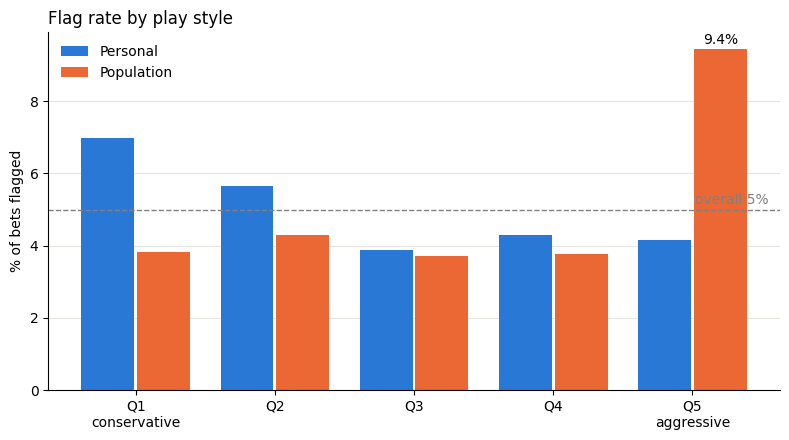

In [27]:
import matplotlib.pyplot as plt

rate = 0.05   # both methods flag their top 5% of bets
pers = (test['s'] >= test['s'].quantile(1 - rate)).groupby(test['style_q'], observed=True).mean() * 100
popl = (test['s_pop'] >= test['s_pop'].quantile(1 - rate)).groupby(test['style_q'], observed=True).mean() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(5)
ax.bar(x - 0.2, pers, 0.38, color='#2a78d6', label='Personal')
ax.bar(x + 0.2, popl, 0.38, color='#eb6834', label='Population')
ax.text(4.2, popl.iloc[4] + 0.15, f'{popl.iloc[4]:.1f}%', ha='center')
ax.axhline(5, color='gray', lw=1, ls='--')
ax.text(4.55, 5.15, 'overall 5%', color='gray', ha='right', fontsize=10)

ax.set_xticks(x, ['Q1\nconservative', 'Q2', 'Q3', 'Q4', 'Q5\naggressive'])
ax.set_ylabel('% of bets flagged')
ax.set_title('Flag rate by play style', loc='left')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(f'fig_style{SUFFIX}.png', dpi=200)
plt.show()

In [29]:
summary = pd.DataFrame({
    '100NL': ['0.74', '1.26×', 'no effect', '1.27×', '8.9% → 4.3%'],
    '200NL': ['0.78', '1.37×', 'no effect', '1.38×', '9.4% → 4.2%'],
}, index=['Baseline R²',
          'Odds of a flag after a large loss',
          'After a large win',
          'Loser vs. bystanders (same table)',
          'Aggressive players flagged (population → personal)'])

(summary.style
    .set_properties(**{'text-align': 'center', 'font-size': '14px', 'padding': '8px 16px'})
    .set_table_styles([
        {'selector': 'th', 'props': [('font-size', '14px'), ('padding', '8px 16px'), ('text-align', 'left')]},
        {'selector': 'thead th', 'props': [('text-align', 'center'), ('font-weight', 'bold')]},
    ]))

,100NL,200NL
Baseline R²,0.74,0.78
Odds of a flag after a large loss,1.26×,1.37×
After a large win,no effect,no effect
Loser vs. bystanders (same table),1.27×,1.38×
Aggressive players flagged (population → personal),8.9% → 4.3%,9.4% → 4.2%


## 12. Save

In [28]:
p.to_parquet(f'bets_scored{SUFFIX}.parquet', index=False)   # eligible players, calibration + test, with resid, mu_p, sigma_p, s, s_pop
#p.to_parquet(f'/content/drive/MyDrive/capstone/bets_scored{SUFFIX}.parquet', index=False)